In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option('display.max_columns', None)
SEED = 42

In [2]:
data = pd.read_csv('dataset/reliabilityRisk2.csv')
print(data.shape)
print(data['Event'].value_counts(normalize=True).round(3))

missing_codes = pd.Series({
    'Gender = -1': (data['Gender'] == -1).sum(),
    'BP = -1': (data['BP'] == -1).sum(),
    'HearRate = -1': (data['HearRate'] == -1).sum(),
    'Albumine = 0': (data['Albumine'] == 0).sum(),
})
display(missing_codes)
display(data.describe().T.round(2))

(1469, 11)
Event
0    0.69
1    0.31
Name: proportion, dtype: float64


Gender = -1      28
BP = -1          19
HearRate = -1    17
Albumine = 0      1
dtype: int64

,count,mean,std,min,25%,50%,75%,max
Gender,1469.0,0.80,0.44,-1.0,1.00,1.00,1.00,1.00
Age,1469.0,67.95,13.23,30.0,58.00,70.00,78.00,101.00
BP,1469.0,138.12,33.73,-1.0,119.78,137.01,155.88,270.61
HearRate,1469.0,75.53,20.10,-1.0,64.00,74.00,86.00,180.00
STelevation,1469.0,0.04,0.19,0.0,0.00,0.00,0.00,1.00
Killip,1469.0,1.47,0.83,1.0,1.00,1.00,2.00,4.00
Albumine,1469.0,38.09,2.77,0.0,37.20,38.20,39.20,48.00
PCR,1469.0,2.62,8.49,0.0,0.50,0.70,1.90,263.00
Troponine,1469.0,47.40,104.04,0.0,1.58,10.20,43.00,1380.00
Creatinine,1469.0,137.71,134.91,24.7,81.00,97.50,135.10,1934.40


In [3]:
clean = data.copy()
clean[['Gender', 'BP', 'HearRate']] = clean[['Gender', 'BP', 'HearRate']].replace(-1, np.nan)
clean['Albumine'] = clean['Albumine'].replace(0, np.nan)

skewed = ['PCR', 'Troponine', 'Creatinine']
clean[skewed] = np.log1p(clean[skewed])

X = clean.drop(columns='Event')
y = clean['Event']
feature_names = list(X.columns)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(X_train.shape, X_test.shape, round(y_train.mean(), 3), round(y_test.mean(), 3))

(1175, 10) (294, 10) 0.311 0.31


In [4]:
prep = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])

candidates = {
    'Logistic regression': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'Random forest': RandomForestClassifier(n_estimators=500, min_samples_leaf=5, class_weight='balanced',
                                            random_state=SEED, n_jobs=-1),
    'KNN (k=31)': KNeighborsClassifier(n_neighbors=31),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for name, clf in candidates.items():
    scores = cross_validate(Pipeline([('prep', clone(prep)), ('clf', clone(clf))]), X_train, y_train, cv=cv,
                            scoring=['roc_auc', 'balanced_accuracy', 'accuracy'])
    rows.append({'Model': name,
                 'AUC': scores['test_roc_auc'].mean(),
                 'Balanced accuracy': scores['test_balanced_accuracy'].mean(),
                 'Accuracy': scores['test_accuracy'].mean()})
display(pd.DataFrame(rows).round(3).sort_values('AUC', ascending=False))

,Model,AUC,Balanced accuracy,Accuracy
0,Logistic regression,0.854,0.775,0.786
2,KNN (k=31),0.849,0.717,0.798
1,Random forest,0.845,0.758,0.764


In [5]:
model = Pipeline([('prep', clone(prep)), ('clf', clone(candidates['Logistic regression']))])
model.fit(X_train, y_train)

p_test = model.predict_proba(X_test)[:, 1]
y_hat_test = (p_test >= 0.5).astype(int)
correct = (y_hat_test == y_test.values).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, y_hat_test).ravel()
print(f'AUC = {roc_auc_score(y_test, p_test):.3f}')
print(f'Accuracy = {accuracy_score(y_test, y_hat_test):.3f}')
print(f'Balanced accuracy = {balanced_accuracy_score(y_test, y_hat_test):.3f}')
print(f'SE = {tp / (tp + fn):.3f}  SP = {tn / (tn + fp):.3f}')
display(pd.DataFrame([[tn, fp], [fn, tp]], index=['Y=0', 'Y=1'], columns=['Ŷ=0', 'Ŷ=1']))

AUC = 0.832
Accuracy = 0.806
Balanced accuracy = 0.778
SE = 0.703  SP = 0.852


,Ŷ=0,Ŷ=1
Y=0,173,30
Y=1,27,64


In [6]:
p_oof = cross_val_predict(clone(model), X_train, y_train, cv=cv, method='predict_proba')[:, 1]
y_hat_oof = (p_oof >= 0.5).astype(int)
y_tr = y_train.values
print(f'Accuracy out-of-fold no treino: {(y_hat_oof == y_tr).mean():.3f}')

scaler = clone(prep).fit(X_train)
Z_train = scaler.transform(X_train)
Z_test = scaler.transform(X_test)

Accuracy out-of-fold no treino: 0.786


In [7]:
def reliability_metrics(k=30):
    nn = NearestNeighbors(n_neighbors=k).fit(Z_train)
    dist_test, idx = nn.kneighbors(Z_test)

    # k + 1 porque o vizinho mais próximo de um ponto de treino é ele próprio
    dist_train, _ = NearestNeighbors(n_neighbors=k + 1).fit(Z_train).kneighbors(Z_train)
    mean_dist_train = dist_train[:, 1:].mean(axis=1)
    d_min, d_max = mean_dist_train.min(), np.percentile(mean_dist_train, 99)

    aed = 1 - np.clip((dist_test.mean(axis=1) - d_min) / (d_max - d_min), 0, 1)
    agreement = (y_hat_oof[idx] == y_tr[idx]).mean(axis=1)
    data_agreement = (y_tr[idx] == y_hat_test[:, None]).mean(axis=1)
    model_agreement = (y_hat_oof[idx] == y_hat_test[:, None]).mean(axis=1)
    combined = aed * data_agreement * model_agreement

    return pd.DataFrame({
        'Density (AED)': aed,
        'Local fit (agreement)': agreement,
        'Data agreement': data_agreement,
        'Model agreement': model_agreement,
        'Combined': combined,
        'Model confidence (baseline)': np.abs(p_test - 0.5) * 2,
    }, index=X_test.index)

K = 30
rel = reliability_metrics(K)
display(rel.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
Density (AED),294.0,0.708,0.216,0.000,0.575,0.769,0.877,0.987
Local fit (agreement),294.0,0.812,0.144,0.500,0.700,0.867,0.933,1.000
Data agreement,294.0,0.784,0.202,0.200,0.667,0.867,0.933,1.000
Model agreement,294.0,0.877,0.186,0.167,0.833,0.967,1.000,1.000
Combined,294.0,0.518,0.265,0.000,0.297,0.532,0.773,0.962
Model confidence (baseline),294.0,0.555,0.278,0.005,0.327,0.599,0.798,1.000


In [8]:
def evaluate_metrics(rel):
    rows = []
    for name in rel.columns:
        r = rel[name].values
        rows.append({'Metric': name,
                     'Pearson r (reliability, correct)': np.corrcoef(r, correct)[0, 1],
                     'AUC (reliability → correct)': roc_auc_score(correct, r)})
    return pd.DataFrame(rows).round(3).sort_values('AUC (reliability → correct)', ascending=False)

display(evaluate_metrics(rel))

,Metric,"Pearson r (reliability, correct)",AUC (reliability → correct)
2,Data agreement,0.358,0.727
3,Model agreement,0.334,0.716
5,Model confidence (baseline),0.257,0.684
4,Combined,0.249,0.673
1,Local fit (agreement),0.222,0.665
0,Density (AED),0.015,0.509


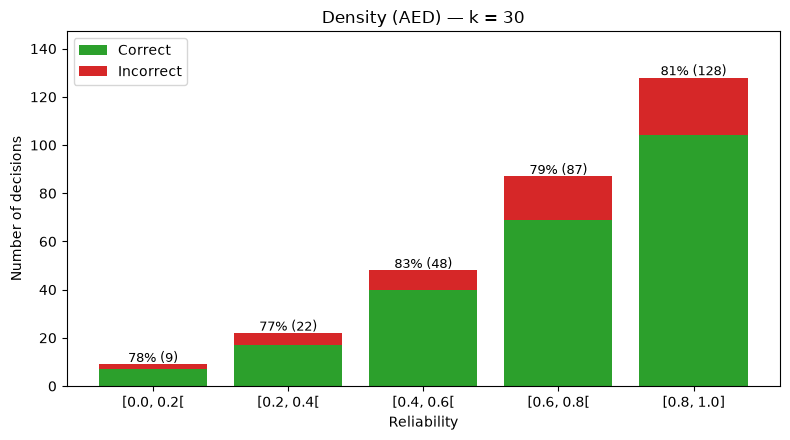

,Bin,N,Correct,Incorrect,% correct
0,"[0.0, 0.2[",9,7,2,77.8
1,"[0.2, 0.4[",22,17,5,77.3
2,"[0.4, 0.6[",48,40,8,83.3
3,"[0.6, 0.8[",87,69,18,79.3
4,"[0.8, 1.0]",128,104,24,81.2


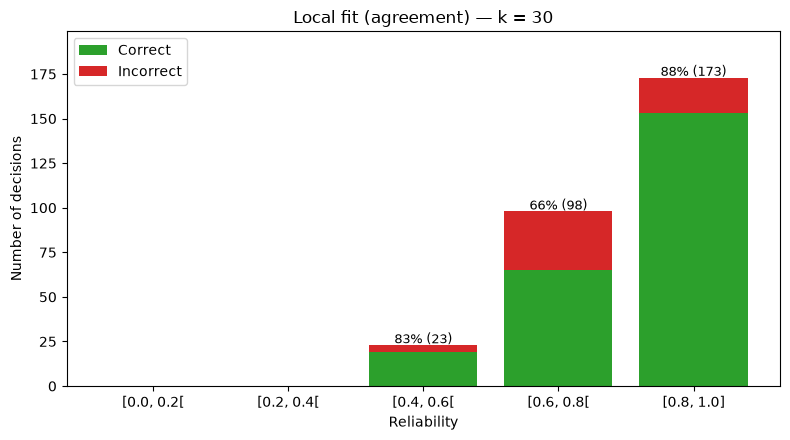

,Bin,N,Correct,Incorrect,% correct
0,"[0.0, 0.2[",0,0,0,NaN
1,"[0.2, 0.4[",0,0,0,NaN
2,"[0.4, 0.6[",23,19,4,82.6
3,"[0.6, 0.8[",98,65,33,66.3
4,"[0.8, 1.0]",173,153,20,88.4


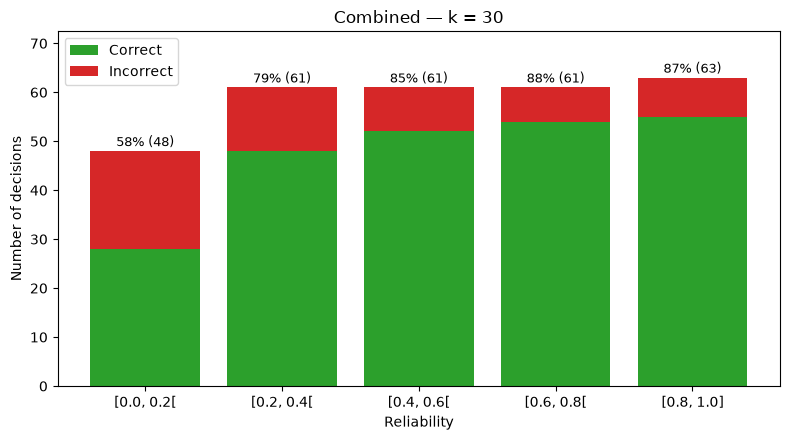

,Bin,N,Correct,Incorrect,% correct
0,"[0.0, 0.2[",48,28,20,58.3
1,"[0.2, 0.4[",61,48,13,78.7
2,"[0.4, 0.6[",61,52,9,85.2
3,"[0.6, 0.8[",61,54,7,88.5
4,"[0.8, 1.0]",63,55,8,87.3


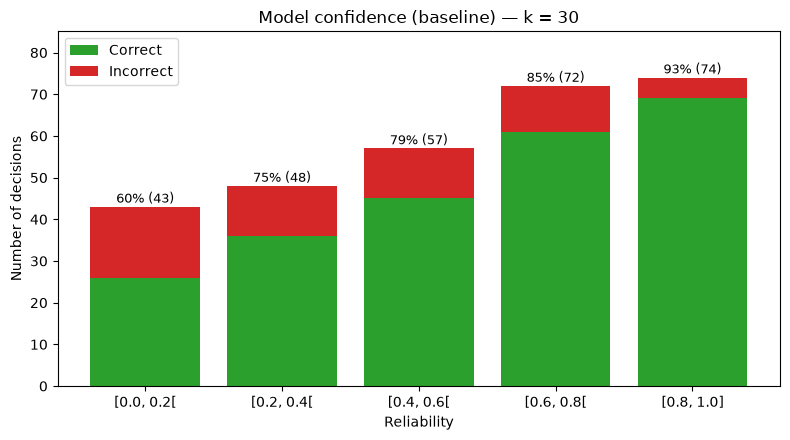

,Bin,N,Correct,Incorrect,% correct
0,"[0.0, 0.2[",43,26,17,60.5
1,"[0.2, 0.4[",48,36,12,75.0
2,"[0.4, 0.6[",57,45,12,78.9
3,"[0.6, 0.8[",72,61,11,84.7
4,"[0.8, 1.0]",74,69,5,93.2


In [9]:
BIN_EDGES = np.array([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
BIN_LABELS = ['[0.0, 0.2[', '[0.2, 0.4[', '[0.4, 0.6[', '[0.6, 0.8[', '[0.8, 1.0]']

def reliability_table(scores, correct):
    bins = np.clip(np.digitize(scores, BIN_EDGES) - 1, 0, len(BIN_LABELS) - 1)
    rows = []
    for b, label in enumerate(BIN_LABELS):
        mask = bins == b
        n = mask.sum()
        n_correct = correct[mask].sum()
        rows.append({'Bin': label, 'N': n, 'Correct': n_correct, 'Incorrect': n - n_correct,
                     '% correct': round(100 * n_correct / n, 1) if n else np.nan})
    return pd.DataFrame(rows)

def plot_reliability(scores, correct, title, fname):
    table = reliability_table(scores, correct)
    x = np.arange(len(table))
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.bar(x, table['Correct'], color='tab:green', label='Correct')
    ax.bar(x, table['Incorrect'], bottom=table['Correct'], color='tab:red', label='Incorrect')
    for i, row in table.iterrows():
        if row['N'] > 0:
            ax.text(i, row['N'] + 1, f"{row['% correct']:.0f}% ({row['N']})", ha='center', fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels(table['Bin'])
    ax.set_ylim(0, table['N'].max() * 1.15)
    ax.set_xlabel('Reliability')
    ax.set_ylabel('Number of decisions')
    ax.set_title(title)
    ax.legend()
    plt.tight_layout()
    plt.savefig(fname, dpi=150)
    plt.show()
    return table

for name, fname in [('Density (AED)', 'rel_density.png'),
                    ('Local fit (agreement)', 'rel_local_fit.png'),
                    ('Combined', 'rel_combined.png'),
                    ('Model confidence (baseline)', 'rel_baseline.png')]:
    display(plot_reliability(rel[name].values, correct, f'{name} — k = {K}', fname))

,Threshold,Coverage,Accuracy,Balanced accuracy,Predicted events,Real events,Sent to review
0,0.0,1.000,0.806,0.778,94,91,0
1,0.2,0.837,0.850,0.775,52,65,48
2,0.4,0.629,0.870,0.614,9,29,109
3,0.6,0.422,0.879,0.500,0,15,170
4,0.8,0.214,0.873,0.500,0,8,231


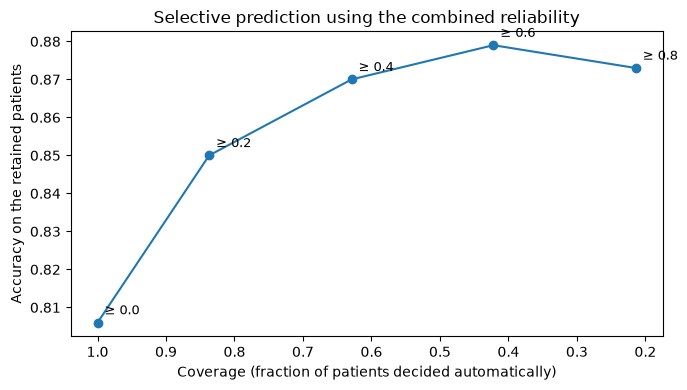

In [10]:
def selective_curve(scores, correct, y_true, y_pred):
    rows = []
    for threshold in [0.0, 0.2, 0.4, 0.6, 0.8]:
        mask = scores >= threshold
        rows.append({'Threshold': threshold,
                     'Coverage': mask.mean(),
                     'Accuracy': correct[mask].mean() if mask.any() else np.nan,
                     'Balanced accuracy': balanced_accuracy_score(y_true[mask], y_pred[mask])
                     if mask.any() and len(np.unique(y_true[mask])) > 1 else np.nan,
                     'Predicted events': y_pred[mask].sum(),
                     'Real events': y_true[mask].sum(),
                     'Sent to review': (~mask).sum()})
    return pd.DataFrame(rows).round(3)

selective = selective_curve(rel['Combined'].values, correct, y_test.values, y_hat_test)
display(selective)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(selective['Coverage'], selective['Accuracy'], marker='o')
for _, row in selective.iterrows():
    ax.annotate(f"≥ {row['Threshold']:.1f}", (row['Coverage'], row['Accuracy']),
                textcoords='offset points', xytext=(5, 6), fontsize=9)
ax.set_xlabel('Coverage (fraction of patients decided automatically)')
ax.set_ylabel('Accuracy on the retained patients')
ax.set_title('Selective prediction using the combined reliability')
ax.invert_xaxis()
plt.tight_layout()
plt.savefig('rel_selective.png', dpi=150)
plt.show()

In [11]:
examples = pd.concat([X_test, y_test], axis=1).copy()
examples[skewed] = np.expm1(examples[skewed])
examples['P(Event)'] = p_test.round(3)
examples['Prediction'] = y_hat_test
examples['Correct'] = correct
examples = examples.join(rel[['Density (AED)', 'Local fit (agreement)', 'Combined']].round(3))

order = rel['Combined'].sort_values().index
display(examples.loc[order[:3]].round(2).T)
display(examples.loc[order[-3:]].round(2).T)

,1164,1440,1263
Gender,1.00,1.00,0.00
Age,82.00,54.00,43.00
BP,77.23,137.99,0.00
HearRate,180.00,71.00,0.00
STelevation,0.00,1.00,0.00
Killip,2.00,2.00,4.00
Albumine,33.00,30.00,34.00
PCR,1.30,11.50,0.20
Troponine,28.70,6.21,3.84
Creatinine,126.30,896.38,73.40


,232,377,1148
Gender,NaN,1.00,1.00
Age,54.00,54.00,66.00
BP,162.83,118.77,152.48
HearRate,73.00,68.00,75.00
STelevation,0.00,0.00,0.00
Killip,1.00,1.00,1.00
Albumine,38.40,36.20,35.80
PCR,0.50,0.50,0.60
Troponine,0.50,4.21,0.97
Creatinine,98.00,75.50,90.40


# Efeito do número de vizinhos (k)

In [ ]:
K_VALUES = [5, 15, 30, 50]
METRICS = ['Density (AED)', 'Local fit (agreement)', 'Data agreement', 'Model agreement', 'Combined']

auc_rows, combined_rows = [], []
for k in K_VALUES:
    rel_k = reliability_metrics(k)

    auc_rows.append({'k': k, **{name: roc_auc_score(correct, rel_k[name]) for name in METRICS}})

    table_k = reliability_table(rel_k['Combined'].values, correct)
    selective_k = selective_curve(rel_k['Combined'].values, correct, y_test.values, y_hat_test)
    selective_k = selective_k[selective_k['Threshold'] == 0.6].iloc[0]
    combined_rows.append({'k': k,
                          'N [0.0, 0.2[': table_k['N'].iloc[0],
                          '% correct [0.0, 0.2[': table_k['% correct'].iloc[0],
                          'N [0.8, 1.0]': table_k['N'].iloc[-1],
                          '% correct [0.8, 1.0]': table_k['% correct'].iloc[-1],
                          'Coverage (>= 0.6)': selective_k['Coverage'],
                          'Accuracy (>= 0.6)': selective_k['Accuracy'],
                          'Predicted events (>= 0.6)': selective_k['Predicted events'],
                          'Real events (>= 0.6)': selective_k['Real events']})

auc_by_k = pd.DataFrame(auc_rows).set_index('k').round(3)
combined_by_k = pd.DataFrame(combined_rows).set_index('k')
baseline_auc = roc_auc_score(correct, rel['Model confidence (baseline)'])

print(f'AUC da confiança do modelo (não depende de k): {baseline_auc:.3f}')
display(auc_by_k)
display(combined_by_k)

fig, ax = plt.subplots(figsize=(7, 4))
for name in METRICS:
    ax.plot(K_VALUES, auc_by_k[name], marker='o', label=name)
ax.axhline(baseline_auc, color='grey', ls='--', label='Model confidence (baseline)')
ax.set_xticks(K_VALUES)
ax.set_xlabel('Number of neighbours (k)')
ax.set_ylabel('AUC (reliability → correct)')
ax.set_title('Effect of k on the reliability metrics')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('rel_k.png', dpi=150)
plt.show()